In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uncertainties

In [2]:
df = pd.read_csv("run_15K.csv")
df.head()

,V_Copper,V_Sapphire,time,sensor_temperature,temperature_setpoint,iTC_P_param,iTC_I_param,iTC_D_param
0,-0.000008,-7.893711e-07,0.000000,14.9116,15.0,2.0,1.0,0.0
1,-0.000008,-9.220185e-07,0.377854,14.8820,15.0,2.0,1.0,0.0
2,-0.000008,-7.541522e-07,0.634356,14.8850,15.0,2.0,1.0,0.0
3,-0.000008,-8.002725e-07,0.886221,14.8862,15.0,2.0,1.0,0.0
4,-0.000007,-6.922541e-07,1.124841,14.9135,15.0,2.0,1.0,0.0


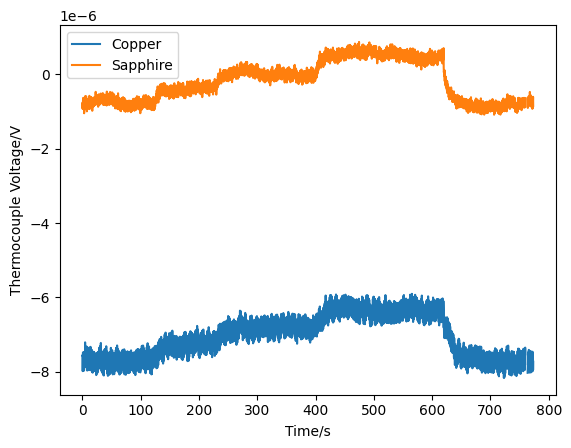

In [3]:
time = df['time']
v_cop = df['V_Copper']
v_sap = df['V_Sapphire']

plt.plot(time, v_cop, label = 'Copper')
plt.plot(time, v_sap, label = 'Sapphire')
plt.legend()
plt.xlabel("Time/s")
plt.ylabel("Thermocouple Voltage/V")
plt.show()

In [4]:
windows = {
    "V_Copper":   [(0, 118), (155, 228), (260, 395), (440, 612), (660, 770)],
    "V_Sapphire": [(0, 118), (145, 228), (255, 395), (425, 612), (660, 770)],
}
v_avg = {}
v_std = {}

for material, times in windows.items():
    print(material)
    v_avg[material] = []
    v_std[material] = []
    for start, end in times:
        in_window = (time >= start) & (time <= end)
        average = df.loc[in_window, material].mean()
        std = df.loc[in_window, material].std()
        v_avg[material].append(average)
        v_std[material].append(std)
        print(f"  {start}-{end} s: {average:.4e} +- {std:.4e} V")

V_Copper
  0-118 s: -7.7038e-06 +- 2.1824e-07 V
  155-228 s: -7.2550e-06 +- 2.2003e-07 V
  260-395 s: -6.8087e-06 +- 2.1749e-07 V
  440-612 s: -6.3418e-06 +- 2.1671e-07 V
  660-770 s: -7.7043e-06 +- 2.1739e-07 V
V_Sapphire
  0-118 s: -7.5610e-07 +- 1.2250e-07 V
  145-228 s: -3.9138e-07 +- 1.1801e-07 V
  255-395 s: 1.5131e-08 +- 1.2570e-07 V
  425-612 s: 5.2745e-07 +- 1.3208e-07 V
  660-770 s: -8.3213e-07 +- 1.1815e-07 V


In [5]:
baseline = {
    "V_Copper": v_avg["V_Copper"][0],
    "V_Sapphire": v_avg["V_Sapphire"][0]
}

v_avg_adj = {}

for material in v_avg.keys():
    v_avg_adj[material] = []
    #print(material)
    for i in range(1, len(v_avg[material])-1):
        v_avg_adj[material].append(v_avg[material][i]-baseline[material])
for material, values in v_avg_adj.items():
    print(material)
    for i, v in enumerate(values, start=1):
        print(f"  Step {i}: {v:.4e} V")


V_Copper
  Step 1: 4.4886e-07 V
  Step 2: 8.9515e-07 V
  Step 3: 1.3620e-06 V
V_Sapphire
  Step 1: 3.6472e-07 V
  Step 2: 7.7124e-07 V
  Step 3: 1.2836e-06 V
